# 01 · Limpieza y filtrado del dataset (@AppleSupport) con PySpark

**Objetivo:** partir del CSV completo de *Customer Support on Twitter* (~3 millones de tweets de varias marcas) y producir un conjunto de datos que contenga **solo** la conversación de `@AppleSupport`: lo que los clientes le escriben y lo que Apple responde.

**Por qué Spark y Parquet:** Spark procesa el CSV de manera distribuida utilizando un esquema explícito (`StructType`) y transformaciones nativas (`pyspark.sql.functions as F`). Al finalizar, el producto de datos filtrado se lleva al Driver con `toPandas()` y se almacena en formato **Parquet** con PyArrow, siguiendo el patrón de los laboratorios para evitar dependencias de `winutils.exe` en Windows.

**Qué produce:** `../data/processed/apple_support_filtrado.parquet` y una tabla de conteos paso a paso para la sección de *Resultados* de la tesis.

## 1. Preparación del entorno e inicialización de Spark
Configuramos las variables de entorno de Python para PySpark (`PYSPARK_PYTHON` y `PYSPARK_DRIVER_PYTHON`) y creamos la `SparkSession` en modo `local[*]` compatible con **Spark 3.5.9**.

In [15]:
# ============================================================
# 1. PREPARACIÓN DEL ENTORNO Y SPARK SESSION
# ============================================================
import os
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, StringType
from pyspark import StorageLevel

# Configuración del entorno Python para PySpark (estilo Laboratorios 6 y 7)
python_executable = sys.executable
os.environ["PYSPARK_PYTHON"] = python_executable
os.environ["PYSPARK_DRIVER_PYTHON"] = python_executable
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"

# Rutas de entrada y salida
RUTA_RAW = Path("../data/raw/twcs.csv")
RUTA_OUT = Path("../data/processed/apple_support_filtrado.parquet")
RUTA_OUT.parent.mkdir(parents=True, exist_ok=True)

BRAND = "AppleSupport"
conteo = {}

# Inicialización de SparkSession (Spark 3.5.9)
spark = (
    SparkSession.builder
    .appName("Tesis_01_Limpieza_AppleSupport")
    .master("local[*]")
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.sql.legacy.timeParserPolicy", "LEGACY")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")
print("Spark:", spark.version)
print("Master:", spark.sparkContext.master)
print("Spark UI:", spark.sparkContext.uiWebUrl)

Spark: 3.5.9
Master: local[*]
Spark UI: http://127.0.0.1:4042


## 2. Ingesta con esquema explícito (`StructType`)
Definimos el esquema explícito para que los identificadores de 18-19 dígitos se lean como `StringType` sin perder precisión, activando `multiLine` y `escape` para manejar saltos de línea y comillas dentro de los tweets.

In [16]:
# ============================================================
# 2. INGESTA DEL CSV CON STRUCTTYPE
# ============================================================
schema_twcs = StructType([
    StructField("tweet_id", StringType(), True),
    StructField("author_id", StringType(), True),
    StructField("inbound", StringType(), True),
    StructField("created_at", StringType(), True),
    StructField("text", StringType(), True),
    StructField("response_tweet_id", StringType(), True),
    StructField("in_response_to_tweet_id", StringType(), True)
])

df_crudo = (
    spark.read
    .schema(schema_twcs)
    .option("header", True)
    .option("multiLine", True)
    .option("escape", '"')
    .csv(str(RUTA_RAW))
)

df_crudo.printSchema()
conteo["total_original"] = df_crudo.count()
print("Total de registros originales:", f"{conteo['total_original']:,}")
display(df_crudo.limit(5).toPandas())

root
 |-- tweet_id: string (nullable = true)
 |-- author_id: string (nullable = true)
 |-- inbound: string (nullable = true)
 |-- created_at: string (nullable = true)
 |-- text: string (nullable = true)
 |-- response_tweet_id: string (nullable = true)
 |-- in_response_to_tweet_id: string (nullable = true)

Total de registros originales: 2,811,774


,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id
0,1,sprintcare,False,Tue Oct 31 22:10:47 +0000 2017,@115712 I understand. I would like to assist y...,2,3
1,2,115712,True,Tue Oct 31 22:11:45 +0000 2017,@sprintcare and how do you propose we do that,NaN,1
2,3,115712,True,Tue Oct 31 22:08:27 +0000 2017,@sprintcare I have sent several private messag...,1,4
3,4,sprintcare,False,Tue Oct 31 21:54:49 +0000 2017,@115712 Please send us a Private Message so th...,3,5
4,5,115712,True,Tue Oct 31 21:49:35 +0000 2017,@sprintcare I did.,4,6


## 3. Selección y filtrado de `@AppleSupport`
Construimos dos subconjuntos y los unimos con `unionByName`:
1. **Respuestas de Apple:** `author_id == "AppleSupport"`.
2. **Tweets de clientes dirigidos a Apple:** tweets entrantes (`inbound == "true"`) que mencionan a `@AppleSupport` o a los que Apple respondió (identificados mediante un `left_semi` join).

In [17]:
# ============================================================
# 3. FILTRO DE LA CONVERSACIÓN DE @AppleSupport
# ============================================================
apple = (
    df_crudo
    .filter(F.col("author_id") == BRAND)
    .withColumn("rol", F.lit("apple"))
)

respondidos = (
    apple
    .select(F.col("in_response_to_tweet_id").alias("tweet_id"))
    .filter(F.col("tweet_id").isNotNull())
    .distinct()
)

clientes = df_crudo.filter(F.lower(F.col("inbound")) == "true")
menciona = clientes.filter(F.col("text").rlike("(?i)@applesupport"))
contestados = clientes.join(respondidos, on="tweet_id", how="left_semi")

clientes_apple = (
    menciona.unionByName(contestados)
    .withColumn("rol", F.lit("cliente"))
)

filtrado = apple.unionByName(clientes_apple)
conteo["tras_filtro_apple"] = filtrado.count()
print("Registros tras filtro AppleSupport:", f"{conteo['tras_filtro_apple']:,}")

Registros tras filtro AppleSupport: 311,379


## 4. Depuración y construcción temporal
Eliminamos duplicados por `tweet_id`, descartamos textos vacíos o nulos y convertimos `created_at` a timestamp probando los formatos del dataset.

In [18]:
# ============================================================
# 4. DEPURACIÓN Y DIMENSIÓN TEMPORAL
# ============================================================
d = filtrado.dropDuplicates(["tweet_id"])
conteo["tras_quitar_duplicados"] = d.count()

d = d.filter(F.col("text").isNotNull() & (F.trim(F.col("text")) != ""))
conteo["tras_quitar_vacios"] = d.count()

col_fecha = F.col("created_at")
d = d.withColumn(
    "fecha",
    F.coalesce(
        F.to_timestamp(col_fecha, "EEE MMM dd HH:mm:ss Z yyyy"),
        F.to_timestamp(col_fecha, "dd/MM/yyyy HH:mm:ss"),
        F.to_timestamp(col_fecha)
    )
)

conteo["fechas_invalidas"] = d.filter(F.col("fecha").isNull()).count()
d = d.filter(F.col("fecha").isNotNull())
print("Registros válidos con fecha:", f"{d.count():,}")

Registros válidos con fecha: 232,973


## 5. Normalización del texto y persistencia
Creamos `texto_limpio` con funciones nativas de Spark (`F.regexp_replace`, `F.trim`, `F.size`, `F.split`) y persistimos el DataFrame con `StorageLevel.MEMORY_AND_DISK` para reutilizarlo en las validaciones y en la exportación final.

In [19]:
# ============================================================
# 5. NORMALIZACIÓN DEL TEXTO Y PERSISTENCIA
# ============================================================
texto_norm = F.regexp_replace(F.col("text"), "[’‘`]", "'")
texto_norm = F.regexp_replace(texto_norm, r"https?://\S+", "<URL>")
texto_norm = F.regexp_replace(texto_norm, r"@(?!(?i:applesupport))\w+", "@USER")
texto_norm = F.trim(F.regexp_replace(texto_norm, r"\s+", " "))

dataset_preparado = (
    d
    .withColumn("texto_limpio", texto_norm)
    .withColumn("n_palabras", F.size(F.split(F.col("texto_limpio"), " ")))
    .select(
        "tweet_id",
        "rol",
        "author_id",
        "fecha",
        "text",
        "texto_limpio",
        "n_palabras",
        "in_response_to_tweet_id"
    )
)

dataset_preparado.persist(StorageLevel.MEMORY_AND_DISK)
print("Registros preparados en caché:", f"{dataset_preparado.count():,}")
display(dataset_preparado.limit(5).toPandas())

Registros preparados en caché: 232,973


,tweet_id,rol,author_id,fecha,text,texto_limpio,n_palabras,in_response_to_tweet_id
0,1000003,cliente,497667,2017-11-05 05:33:26,@AppleSupport https://t.co/OnHabGwPo7,@USER <URL>,2,999856
1,1000023,apple,AppleSupport,2017-11-03 16:45:53,@356755 We'd be happy to look this over with y...,@USER We'd be happy to look this over with you...,24,1000024
2,1000077,apple,AppleSupport,2017-11-03 16:57:27,@356765 We're here to help. What happens when ...,@USER We're here to help. What happens when yo...,28,1000078
3,1000092,cliente,356770,2017-11-03 12:52:55,"@AppleSupport your c/s sucks, I was just disco...","@USER your c/s sucks, I was just disconnected ...",15,NaN
4,1000186,cliente,356792,2017-11-03 12:43:38,@115858 @AppleSupport y’all need to fix this ...,@USER @USER y'all need to fix this fr I️ shoul...,16,NaN


In [20]:
# Ver datos de fecha que contiene 2016
# Ver datos con fecha en 2016
dataset_preparado.filter(F.year("fecha") == 2016).show(truncate=False)

+--------+-------+------------+-------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------+------------------------------------------------------------------------------------------------------------------------------------------+----------+-----------------------+
|tweet_id|rol    |author_id   |fecha              |text                                                                                                                                                                |texto_limpio                                                                                                                              |n_palabras|in_response_to_tweet_id|
+--------+-------+------------+-------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------+--

## 6. Resumen para la sección de Resultados
Documentamos cuántos tweets había al inicio, cuántos quedaron tras cada etapa y el desglose entre clientes y respuestas de Apple.

In [21]:
# ============================================================
# 6. RESUMEN DE CONTEOS Y VALIDACIÓN
# ============================================================
resumen_roles = (
    dataset_preparado
    .groupBy("rol")
    .count()
    .toPandas()
    .set_index("rol")["count"]
    .to_dict()
)

rango_fechas = (
    dataset_preparado
    .agg(
        F.min("fecha").alias("inicio"),
        F.max("fecha").alias("fin")
    )
    .collect()[0]
)

conteo["tweets_clientes"] = int(resumen_roles.get("cliente", 0))
conteo["respuestas_apple"] = int(resumen_roles.get("apple", 0))
conteo["fecha_inicio"] = str(rango_fechas["inicio"])
conteo["fecha_fin"] = str(rango_fechas["fin"])

df_resumen = pd.Series(conteo, name="valor").to_frame()
display(df_resumen)

,valor
total_original,2811774
tras_filtro_apple,311379
tras_quitar_duplicados,232973
tras_quitar_vacios,232973
fechas_invalidas,0
tweets_clientes,126113
respuestas_apple,106860
fecha_inicio,2016-03-03 07:00:08
fecha_fin,2017-12-03 17:12:28


## 7. Exploración rápida
Estadísticos de longitud de palabras y serie diaria de volumen de tweets.

+-------+-----------------+
|summary|       n_palabras|
+-------+-----------------+
|  count|           232973|
|   mean|20.37012014267748|
| stddev|9.259212279520792|
|    min|                1|
|    max|               94|
+-------+-----------------+



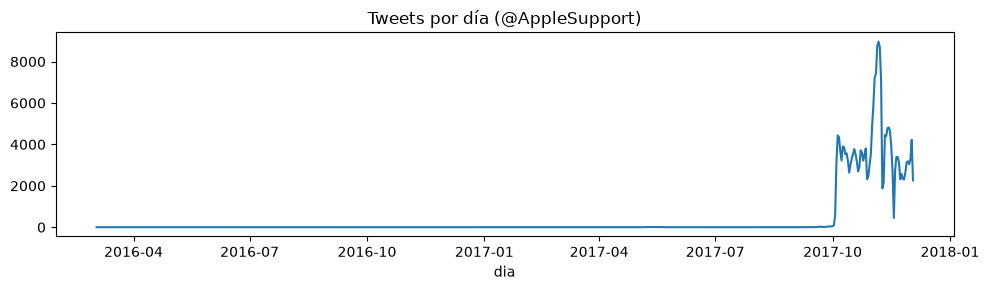

In [22]:
# ============================================================
# 7. EXPLORACIÓN DE LONGITUD Y VOLUMEN DIARIO
# ============================================================
dataset_preparado.select("n_palabras").describe().show()

por_dia = (
    dataset_preparado
    .groupBy(F.to_date("fecha").alias("dia"))
    .count()
    .orderBy("dia")
    .toPandas()
)
por_dia.set_index("dia")["count"].plot(figsize=(10, 3), title="Tweets por día (@AppleSupport)")
plt.tight_layout()
plt.show()

## 8. Salida en Parquet, verificación y cierre de sesión
Convertimos el producto de datos filtrado a pandas para guardarlo en formato Parquet con compresión `snappy`, verificamos la lectura y liberamos los recursos de Spark.

In [23]:
# ============================================================
# 8. GUARDADO EN PARQUET Y CIERRE DE SPARK
# ============================================================
dataset_preparado_pd = dataset_preparado.toPandas()
dataset_preparado_pd.to_parquet(
    RUTA_OUT,
    index=False,
    engine="pyarrow",
    compression="snappy",
    coerce_timestamps="us",
    allow_truncated_timestamps=True
)

df_verificacion = pd.read_parquet(RUTA_OUT)
print("Ruta de salida:", RUTA_OUT.resolve())
print("Registros enviados:", len(dataset_preparado_pd))
print("Registros recuperados:", len(df_verificacion))

dataset_preparado.unpersist(blocking=True)
spark.stop()
print("SparkSession detenida.")

Ruta de salida: C:\Users\julia\OneDrive\Escritorio\MCD\Tesis\proyecto_investigacion\data\processed\apple_support_filtrado.parquet
Registros enviados: 232973
Registros recuperados: 232973
SparkSession detenida.
